# M05-3 | 逐層診斷：量化誤差從哪一層開始變大

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m05_ptq_pipeline/03_layerwise_sqnr.ipynb)

整體的輸出 SQNR 只告訴你「有問題」，不告訴你「在哪」。torchao 的 numeric debugger 把量化前後兩張圖逐 node 對齊，每個位置各給一個 SQNR。

- **A.** 用 numeric debugger 取得逐 node 的 SQNR。
- **B.** 怎麼讀：整體趨勢、為什麼不是逐層穩定下降、掉最多的位置。
- **C.** 參考圖要用哪一張。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m05_ptq_pipeline")

In [1]:
import copy
from typing import Any, cast

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, trained_tiny_net
from common.models import example_inputs
from common.pt2e import (
    compare_results,
    convert_pt2e,
    export_module,
    extract_results_from_loggers,
    get_xnnpack_quantizer,
    prepare_for_propagation_comparison,
    prepare_pt2e,
    quiet,
)
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"

## A. 逐 node 的 SQNR

numeric debugger 的流程有三步，API 都從 `common/pt2e.py` 匯出：

1. `prepare_for_propagation_comparison(圖)`：複製一份圖，在每個 node 後面接一個 logger，記下它的輸出。
2. 參考圖與量化圖各跑同一批輸入，`extract_results_from_loggers` 取出每個 logger 記到的值。
3. `compare_results(參考, 量化)`：依 node 的來源資訊把兩邊對齊，每個位置算一個 SQNR。

**參考圖**用 `prepare_pt2e` 之後、校準之前的圖：BN 已經折掉，observer 還沒看過資料，只觀察、不改數值，
等於「折完 BN 的 fp32」，每個運算都和量化圖一一對應（C 段說明為什麼不能用 export 的原圖）。

舊版教學會在 export 後呼叫 `generate_numeric_debug_handle(ep)`；torchao 0.18 的原始碼註解寫明它已不需要、只為了相容而保留，這裡不呼叫。

In [2]:
def build(model):
    """回傳 (參考圖, 量化圖)：參考圖是 prepare 之後、校準之前的複本。"""
    prepared = prepare_pt2e(export_module(model, example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
    ref = copy.deepcopy(prepared)
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return ref, convert_pt2e(prepared)


def module_of(gm, node_name):
    """node 屬於哪個 module（看 nn_module_stack）；observer 沒有 module，改看它量化的 node。"""
    node = next(n for n in gm.graph.nodes if n.name == node_name)
    if node.op == "call_module" and "activation_post_process" in node.target:
        node = node.args[0]
    stack = node.meta.get("nn_module_stack") or {}
    return (list(stack.values())[-1][0] if stack else "") or "(top)"


def layerwise_sqnr(ref_gm, quant_gm, x):
    """兩張圖跑同一批 x，回傳 [(module, SQNR), ...]，依圖上的順序。"""
    labels = {n.name: module_of(ref_gm, n.name) for n in ref_gm.graph.nodes}  # 接 logger 之前先記下
    ref_l, quant_l = prepare_for_propagation_comparison(ref_gm), prepare_for_propagation_comparison(quant_gm)
    with torch.no_grad():
        ref_l(x)
        quant_l(x)
    # torchao 的型別標註和實際回傳值不符（extract 回傳 list[object]、compare 要 list[Tensor]），所以略過型別檢查
    summaries = compare_results(
        extract_results_from_loggers(ref_l),  # pyright: ignore[reportArgumentType]
        extract_results_from_loggers(quant_l),  # pyright: ignore[reportArgumentType]
    )
    return [(labels[s.ref_node_name], float(cast(Any, s.results[0].sqnr))) for s in summaries.values()]


model = trained_tiny_net()
(x,) = next(calibration_batches(64, seed=9))
ref, quant = build(model)
result = layerwise_sqnr(ref, quant, x)
names, scores = [m for m, _ in result], [s for _, s in result]
drops = [scores[i] - scores[i - 1] for i in range(1, len(scores))]
worst = 1 + min(range(len(drops)), key=lambda i: drops[i])  # 比前一個位置掉最多的位置

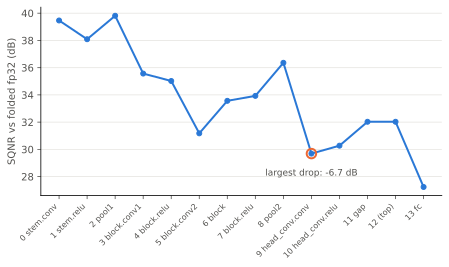

In [3]:
#| code-fold: true
#| code-summary: 畫圖的程式
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(range(len(scores)), scores, color=BLUE, lw=2, marker="o", ms=5)
ax.scatter([worst], [scores[worst]], s=90, facecolors="none", edgecolors=ORANGE, linewidths=2, zorder=3)
ax.annotate(f"largest drop: {drops[worst - 1]:+.1f} dB", (worst, scores[worst]), xytext=(0, -22),
            textcoords="offset points", ha="center", color=MUTED, fontsize=9)
ax.set_xticks(range(len(scores)), [f"{i} {n}" for i, n in enumerate(names)], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("SQNR vs folded fp32 (dB)", color=MUTED)
ax.grid(axis="y", color="#e6e5e1", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [4]:
table([[i, m, f"{s:.1f}", "—" if i == 0 else f"{s - scores[i - 1]:+.1f}"] for i, (m, s) in enumerate(result)],
      ["#", "module", "SQNR (dB)", "比前一個位置"])

#,module,SQNR (dB),比前一個位置
0,stem.conv,39.5,—
1,stem.relu,38.1,-1.4
2,pool1,39.8,+1.7
3,block.conv1,35.6,-4.2
4,block.relu,35.0,-0.5
5,block.conv2,31.2,-3.8
6,block,33.6,+2.4
7,block.relu,33.9,+0.4
8,pool2,36.4,+2.4
9,head_conv.conv,29.7,-6.7


每個位置的數字，是「量化圖在這個 node 的輸出」對「參考圖在同一個 node 的輸出」的 SQNR。
同一批輸入從頭跑到這裡，所以它累積了前面所有層的誤差。`(top)` 是不屬於任何子模組的 node（`flatten`）。

## B. 怎麼讀

In [5]:
ups = sum(d > 0 for d in drops)
print(f"整體：從 {scores[0]:.1f} dB 降到 {scores[-1]:.1f} dB；{len(drops)} 步裡有 {ups} 步回升")
print(f"比前一個位置掉最多：第 {worst} 個位置（{names[worst]}，{drops[worst - 1]:+.1f} dB）")
assert scores[-1] < scores[0] and ups > 0

整體：從 39.5 dB 降到 27.2 dB；13 步裡有 6 步回升
比前一個位置掉最多：第 9 個位置（head_conv.conv，-6.7 dB）


- **趨勢是往後走低**：越靠近輸出，累積的量化誤差越多。累積的直接證據在 M05-4 D 段：只量化前 k 個 module，k 越大整體 SQNR 越低。
- **但不是逐層穩定下降**：有好幾步是回升的。每個位置的訊號大小與分布不同，誤差相對於訊號的比例（SQNR）不一定單調。這是推論，這裡沒有逐項拆解。
- **每一步的下降量混合了兩件事**：這一層自己的量化誤差，以及前面傳下來的誤差（可能被這層放大，推論）。
  掉最多的位置是一條線索，但 M05-4 會看到：把它留在 fp32 不一定最有用，真正影響整體 SQNR 最大的是最後的 `fc`。

所以逐層 SQNR 用來**縮小範圍**：先看整體 SQNR 判斷有沒有問題，再用逐層 SQNR 找候選，最後用實驗確認（M05-4）。

## C. 參考圖要用哪一張

直覺上會拿 export 的原圖當參考。試試看：

In [6]:
gm = export_module(model, example_inputs())
from_export = layerwise_sqnr(gm, copy.deepcopy(quant), x)
print(f"參考圖 = prepare 之後的圖：對上 {len(result)} 個位置")
print(f"參考圖 = export 的原圖：  對上 {len(from_export)} 個位置")
assert len(result) > 0 and len(from_export) == 0

參考圖 = prepare 之後的圖：對上 14 個位置
參考圖 = export 的原圖：  對上 0 個位置


在 torchao 0.18 上，export 的原圖一個位置都對不上，`compare_results` 回傳空的結果，不會報錯。
推論（這裡沒有追原始碼的對齊細節）：對齊依據的是 `prepare_pt2e` 處理過的 node 來源資訊，沒經過 prepare 的圖沒有對應的資訊。

就算對得上，export 的原圖還有沒折的 BN，conv 的輸出和量化圖本來就不是同一個運算，比出來的低 SQNR 是假警報。
「prepare 之後、校準之前」的圖兩個問題都沒有：運算和量化圖相同，差別只有量化。

## 小結

- numeric debugger 給每個位置一個 SQNR，累積了前面所有層的誤差；整體往後走低，但不單調。
- 掉最多的位置是線索，不是結論，要用實驗確認（M05-4）。
- 參考圖用「prepare 之後、校準之前」的複本；export 的原圖對不上任何位置。